In [1]:
import random
import copy
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms
import torchvision.transforms.functional as TF
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt


def set_global_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

import logging

# Configure logging to overwrite "_.log" every run (mode="w")
logging.basicConfig(
    level=logging.INFO,
    format="%(message)s",
    handlers=[
        logging.FileHandler("q1_a.log", mode="w"),  # "w" overwrites, "a" appends
        logging.StreamHandler()
    ],
    force=True  # Resets any existing logging handlers
)
logger = logging.getLogger(__name__)

In [2]:
class CIFAR10Subset(Dataset):
    def __init__(self, images, labels, transform=None):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        img = self.images[idx]
        label = int(self.labels[idx])
        if self.transform:
            img = self.transform(img)
        return img, label


def prepare_cifar10(seed=260007, data_dir="./data", batch_size=1024, num_workers=2):
    set_global_seed(seed)

    raw_train = datasets.CIFAR10(root=data_dir, train=True, download=True)
    raw_test = datasets.CIFAR10(root=data_dir, train=False, download=True)

    all_train_images = raw_train.data
    all_train_labels = np.array(raw_train.targets)

    indices = np.arange(len(all_train_labels))
    train_idx, val_idx = train_test_split(
        indices, test_size=5000, random_state=seed, stratify=all_train_labels
    )

    X_train, y_train = all_train_images[train_idx], all_train_labels[train_idx]
    X_val, y_val = all_train_images[val_idx], all_train_labels[val_idx]
    X_test, y_test = raw_test.data, np.array(raw_test.targets)

    train_float = X_train.astype(np.float32) / 255.0
    mean = train_float.mean(axis=(0, 1, 2)).tolist()
    std = train_float.std(axis=(0, 1, 2)).tolist()

    # NO augmentation during training (as per hypothesis)
    base_transform = transforms.Compose([
        transforms.ToPILImage(),
        transforms.ToTensor(),
        transforms.Normalize(mean=mean, std=std),
    ])

    train_dataset = CIFAR10Subset(X_train, y_train, transform=base_transform)
    val_dataset = CIFAR10Subset(X_val, y_val, transform=base_transform)
    test_dataset = CIFAR10Subset(X_test, y_test, transform=base_transform)

    g = torch.Generator()
    g.manual_seed(seed)

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=num_workers, generator=g)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=num_workers)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=num_workers)

    splits_numpy = {
        "X_val": X_val, "y_val": y_val,
        "mean": mean, "std": std,
        "classes": raw_train.classes
    }
    return train_loader, val_loader, test_loader, splits_numpy

In [3]:
class MLPRegularized(nn.Module):
    def __init__(self, dropout_p=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(3072, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(dropout_p),
            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(dropout_p),
            nn.Linear(64, 10)
        )

    def forward(self, x):
        return self.net(x)


class ConvNetMatched(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),    # 32x32x32
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),                               # 16x16x32
            nn.Conv2d(32, 64, kernel_size=3, padding=1),   # 16x16x64
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),                               # 8x8x64
            nn.Conv2d(64, 128, kernel_size=3, padding=1),  # 8x8x128
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),                               # 4x4x128 = 2048
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(2048, 150),
            nn.ReLU(),
            nn.Linear(150, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

In [4]:
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            total_loss += criterion(out, y).item() * y.size(0)
            correct += (out.argmax(dim=1) == y).sum().item()
            total += y.size(0)
    return total_loss / total, 100.0 * correct / total


def train_model(model, train_loader, val_loader, name, epochs=30, lr=1e-3, weight_decay=0.0, device="cpu"):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val_acc = 0.0
    best_weights = copy.deepcopy(model.state_dict())

    for epoch in range(1, epochs + 1):
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            out = model(x)
            loss = criterion(out, y)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * y.size(0)
            correct += (out.argmax(dim=1) == y).sum().item()
            total += y.size(0)

        train_loss = running_loss / total
        train_acc = 100.0 * correct / total
        val_loss, val_acc = evaluate(model, val_loader, criterion, device)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_weights = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_weights)
    torch.save(model.state_dict(), name + ".pt")
    return model, history, best_val_acc

In [ ]:
def evaluate_translation_shifts(models_dict, X_val, y_val, mean, std, shifts=(-6, -4, -2, 0, 2, 4, 6), device="cpu"):
    shift_results = {name: [] for name in models_dict}
    criterion = nn.CrossEntropyLoss()

    for dx in shifts:
        shift_transform = transforms.Compose([
            transforms.ToPILImage(),
            transforms.Pad(8, padding_mode="edge"),
            transforms.Lambda(lambda img: TF.affine(img, angle=0, translate=(dx, 0), scale=1.0, shear=0)),
            transforms.CenterCrop(32),
            transforms.ToTensor(),
            transforms.Normalize(mean=mean, std=std),
        ])
        shifted_val = CIFAR10Subset(X_val, y_val, transform=shift_transform)
        shifted_loader = DataLoader(shifted_val, batch_size=256, shuffle=False)

        for name, model in models_dict.items():
            _, acc = evaluate(model, shifted_loader, criterion, device)
            shift_results[name].append(acc)

    return shifts, shift_results

def plot_training_curves(histories, save_path="q1_part_a_train_val_curves.png"):
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    colors = {"MLP-Regularized": "#7570b3", "ConvNet-Matched": "#1b9e77"}

    for name, hist in histories.items():
        epochs = range(1, len(hist["train_acc"]) + 1)
        c = colors[name]
        # Accuracy
        axes[0].plot(epochs, hist["train_acc"], linestyle="--", color=c, alpha=0.75, label=f"{name} (Train)")
        axes[0].plot(epochs, hist["val_acc"], linestyle="-", linewidth=2, color=c, label=f"{name} (Val)")
        # Loss
        axes[1].plot(epochs, hist["train_loss"], linestyle="--", color=c, alpha=0.75, label=f"{name} (Train)")
        axes[1].plot(epochs, hist["val_loss"], linestyle="-", linewidth=2, color=c, label=f"{name} (Val)")

    axes[0].set_title("Train vs. Validation Accuracy (No Augmentation)")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Accuracy (%)")
    axes[0].grid(True, alpha=0.3)
    axes[0].legend(fontsize=9)

    axes[1].set_title("Train vs. Validation Loss")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Cross-Entropy Loss")
    axes[1].grid(True, alpha=0.3)
    axes[1].legend(fontsize=9)

    plt.tight_layout()
    plt.savefig(save_path, dpi=300)
    plt.show()


def plot_translation_sensitivity(shifts, shift_results, X_val, y_val, classes, models_dict, mean, std, device="cpu", save_path="q1_part_a_translation_analysis.png"):
    fig = plt.figure(figsize=(14, 5))
    gs = fig.add_gridspec(1, 2, width_ratios=[1.3, 1.0])

    ax0 = fig.add_subplot(gs[0])
    colors = {"MLP-Regularized": "#7570b3", "ConvNet-Matched": "#1b9e77"}
    for name, accs in shift_results.items():
        ax0.plot(shifts, accs, marker="o", linewidth=2.2, color=colors[name], label=name)

    ax0.axvline(0, color="gray", linestyle=":", label="Original Alignment (0 px)")
    ax0.set_title("Validation Accuracy Under Horizontal Pixel Shifts")
    ax0.set_xlabel("Horizontal Translation Shift (pixels)")
    ax0.set_ylabel("Validation Accuracy (%)")
    ax0.set_xticks(shifts)
    ax0.grid(True, alpha=0.3)
    ax0.legend()

    sample_idx = 12
    raw_img = X_val[sample_idx]
    true_label = classes[y_val[sample_idx]]

    sub_gs = gs[1].subgridspec(1, 3, wspace=0.15)
    demo_shifts = [-5, 0, +5]

    for i, dx in enumerate(demo_shifts):
        ax = fig.add_subplot(sub_gs[i])
        pil_padded = TF.pad(transforms.ToPILImage()(raw_img), 8, padding_mode="edge")
        shifted_pil = TF.center_crop(TF.affine(pil_padded, angle=0, translate=(dx, 0), scale=1.0, shear=0), 32)

        tensor_img = transforms.Normalize(mean=mean, std=std)(transforms.ToTensor()(shifted_pil)).unsqueeze(0).to(device)
        mlp_pred = classes[models_dict["MLP-Regularized"](tensor_img).argmax(dim=1).item()]
        cnn_pred = classes[models_dict["ConvNet-Matched"](tensor_img).argmax(dim=1).item()]

        ax.imshow(shifted_pil)
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_title(f"Shift: {dx:+d} px\nTrue: {true_label}\nMLP: {mlp_pred}\nCNN: {cnn_pred}", fontsize=8.5)

    plt.tight_layout()
    plt.savefig(save_path, dpi=300)
    plt.show()

Running on device: cuda
100%|██████████| 170M/170M [15:58<00:00, 178kB/s] 

--- Model Parameter Comparison ---
MLP-Regularized Params: 402,634
ConvNet-Matched Params: 402,556

Training MLP-Regularized...
Training ConvNet-Matched...


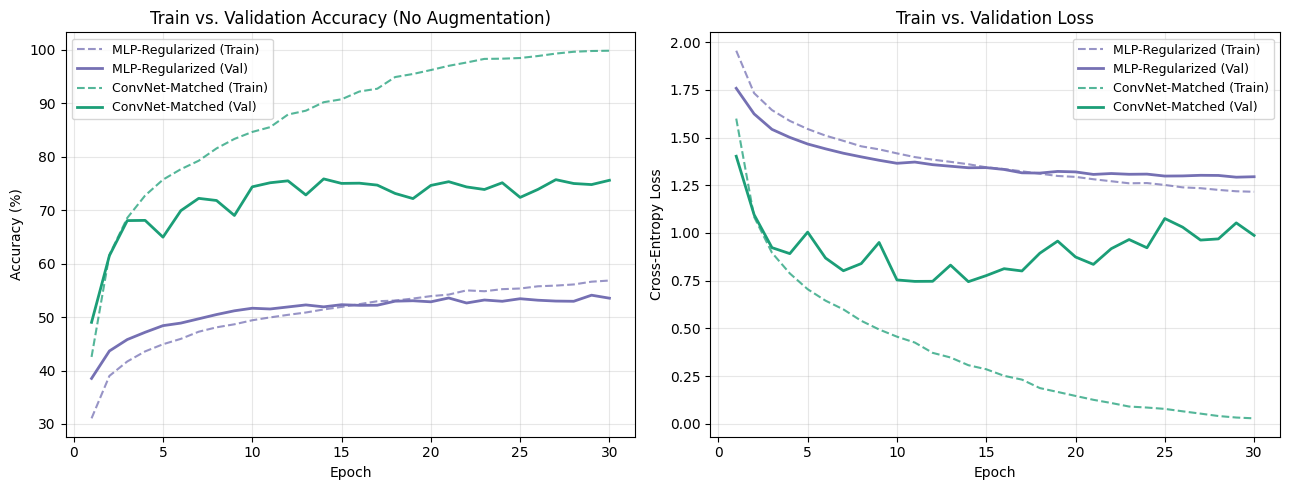


--- Validation Accuracy Across Horizontal Shifts ---
MLP-Regularized  | 0px: 54.10% | -4px: 46.46% | +4px: 46.10% | -6px: 42.14% (Drop: 11.96%)
ConvNet-Matched  | 0px: 75.86% | -4px: 68.78% | +4px: 69.58% | -6px: 60.62% (Drop: 15.24%)


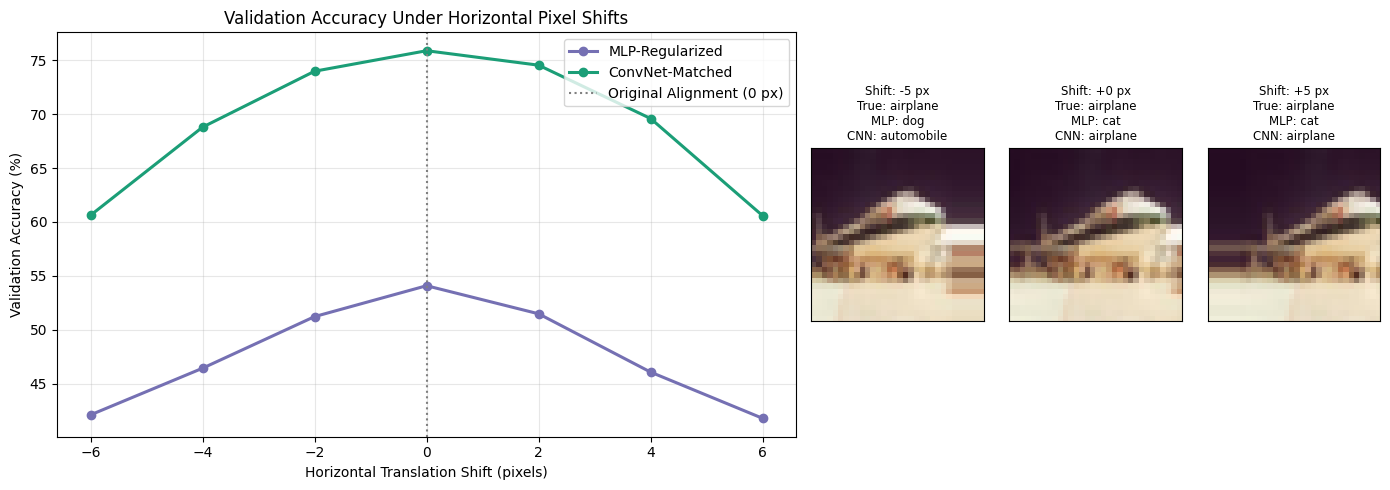


--- Final Official Test Set Results (Evaluated Once After Locking Choices) ---
MLP-Regularized | Best Val: 54.10% | Final Test: 54.04%
ConvNet-Matched | Best Val: 75.86% | Final Test: 75.22%


In [6]:
if __name__ == "__main__":
    SEED = 260007
    EPOCHS = 30
    BATCH_SIZE = 1024
    LR = 1e-3
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
    logger.info(f"Running on device: {DEVICE}")

    train_loader, val_loader, test_loader, splits = prepare_cifar10(seed=SEED, batch_size=BATCH_SIZE)

    set_global_seed(SEED)
    mlp_reg = MLPRegularized(dropout_p=0.3)
    set_global_seed(SEED)
    cnn_matched = ConvNetMatched()

    logger.info("\n--- Model Parameter Comparison ---")
    logger.info(f"MLP-Regularized Params: {count_parameters(mlp_reg):,}")
    logger.info(f"ConvNet-Matched Params: {count_parameters(cnn_matched):,}")

    # Train both models under identical budget (30 epochs, Adam lr=1e-3, no augmentation)
    logger.info("\nTraining MLP-Regularized...")
    mlp_reg, hist_reg, best_val_reg = train_model(
        mlp_reg, train_loader, val_loader, name = "mlp_reg", epochs=EPOCHS, lr=LR, weight_decay=1e-4, device=DEVICE
    )

    logger.info("Training ConvNet-Matched...")
    cnn_matched, hist_cnn, best_val_cnn = train_model(
        cnn_matched, train_loader, val_loader, name = "cnn_matched", epochs=EPOCHS, lr=LR, weight_decay=1e-4, device=DEVICE
    )

    histories = {"MLP-Regularized": hist_reg, "ConvNet-Matched": hist_cnn}
    plot_training_curves(histories)

    models_dict = {"MLP-Regularized": mlp_reg, "ConvNet-Matched": cnn_matched}
    shifts, shift_results = evaluate_translation_shifts(
        models_dict, splits["X_val"], splits["y_val"], splits["mean"], splits["std"], device=DEVICE
    )

    logger.info("\n--- Validation Accuracy Across Horizontal Shifts ---")
    for name, accs in shift_results.items():
        drop_6px = accs[3] - accs[0]  # 0px vs -6px
        logger.info(f"{name:16s} | 0px: {accs[3]:.2f}% | -4px: {accs[1]:.2f}% | +4px: {accs[5]:.2f}% | -6px: {accs[0]:.2f}% (Drop: {drop_6px:.2f}%)")

    plot_translation_sensitivity(
        shifts, shift_results, splits["X_val"], splits["y_val"], splits["classes"],
        models_dict, splits["mean"], splits["std"], device=DEVICE
    )

    criterion = nn.CrossEntropyLoss()
    _, test_acc_reg = evaluate(mlp_reg, test_loader, criterion, DEVICE)
    _, test_acc_cnn = evaluate(cnn_matched, test_loader, criterion, DEVICE)

    logger.info("\n--- Final Official Test Set Results (Evaluated Once After Locking Choices) ---")
    logger.info(f"MLP-Regularized | Best Val: {best_val_reg:.2f}% | Final Test: {test_acc_reg:.2f}%")
    logger.info(f"ConvNet-Matched | Best Val: {best_val_cnn:.2f}% | Final Test: {test_acc_cnn:.2f}%")

In [7]:
logger.info("\n--- Validation Accuracy & Relative Drop Across Horizontal Shifts ---")
zero_idx = shifts.index(0)

for name, accs in shift_results.items():
    base_acc = accs[zero_idx]
    acc_m4 = accs[shifts.index(-4)]
    acc_p4 = accs[shifts.index(4)]
    acc_m6 = accs[shifts.index(-6)]
    acc_p6 = accs[shifts.index(6)]

    raw_drop_m6 = base_acc - acc_m6

    rel_drop_m6 = (raw_drop_m6 / base_acc) * 100.0

    logger.info(
        f"{name:16s} | 0px: {base_acc:.2f}% | -4px: {acc_m4:.2f}% | +4px: {acc_p4:.2f}% | "
        f"-6px: {acc_m6:.2f}% | +6px: {acc_p6:.2f}%"
    )
    logger.info(
        f"{'':16s} -> At -6px: Raw Drop = {raw_drop_m6:.2f}% | "
        f"Relative Drop = {rel_drop_m6:.2f}%"
    )


--- Validation Accuracy & Relative Drop Across Horizontal Shifts ---
MLP-Regularized  | 0px: 54.10% | -4px: 46.46% | +4px: 46.10% | -6px: 42.14% | +6px: 41.82%
                 -> At -6px: Raw Drop = 11.96% | Relative Drop = 22.11%
ConvNet-Matched  | 0px: 75.86% | -4px: 68.78% | +4px: 69.58% | -6px: 60.62% | +6px: 60.58%
                 -> At -6px: Raw Drop = 15.24% | Relative Drop = 20.09%
